# Models: load an exported model and score with numpy

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leon1706-lol/Aether-quant/blob/main/notebooks/04_models.ipynb)

`aether_quant.models` loads any folder that holds an exported model and its feature schema, and scores a close table with the library's numpy forward pass: no torch. Each GitHub release publishes two small example models trained on the bundled sample (`aq models install example-crypto-mlp`); the project's own trading models are not published.

This notebook stays offline. It writes a hand-made one-layer model in the export format, so the steps are the same as for a trained example or your own retrain's `ml/versions/<id>/`.

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: install the library (numpy and pandas come with it)
    get_ipython().run_line_magic("pip", 'install -q "aether-quant[notebooks]"')  # noqa: F821
else:  # a clone: run against the checkout's code
    for parent in (Path.cwd(), *Path.cwd().parents):
        if (parent / "aether_quant" / "__init__.py").is_file():
            sys.path.insert(0, str(parent))
            break

## The catalog

The examples each release carries. `models.install(name)` downloads one, checks its sha256 against the release's manifest and unpacks it into `~/.cache/aether-quant/models`; `models.load(name)` then opens it.

In [2]:
import pandas as pd

from aether_quant import models, samples

pd.DataFrame(models.catalog())[["name", "kind", "summary"]]

,name,kind,summary
0,example-crypto-mlp,multitask,A small multitask network on six return and vo...
1,example-crypto-seq,sequence,A small causal convolutional network over 20 s...


## The features

Six features per coin and session, each from closes up to that session only, z-scored across the coins of the date: returns over 1, 5, 20 and 60 sessions and volatility over 20 and 60.

In [3]:
closes = samples.load_sample_prices()
features = models.example_features(closes)
names = [column for column in features.columns if column not in ("date", "ticker")]
features.dropna().tail()

,date,ticker,ret_1,ret_5,ret_20,ret_60,vol_20,vol_60
21764,2026-10-31,LINKUSD,2.029921,1.405046,-0.179232,-0.076576,0.877076,0.186644
21765,2026-10-31,LTCUSD,0.114071,0.084177,-0.345506,0.464480,-0.007340,-0.191771
21766,2026-10-31,XLMUSD,-0.176752,0.744604,-0.765248,-0.515235,-0.070052,-0.030075
21767,2026-10-31,XRPUSD,0.201075,-0.752116,0.052487,-0.759684,-0.450855,-0.464840
21768,2026-10-31,ZECUSD,-0.719141,1.224175,1.551095,2.819098,2.397237,2.389311


## A model folder

The export format is a list of layers and a state dict. This one is linear: 20-session momentum minus half the 20-session volatility, read through one `rank_20d` head.

In [4]:
import json
import tempfile

folder = Path(tempfile.mkdtemp()) / "momentum-minus-volatility"
folder.mkdir(parents=True)
export = {"trunk": [{"type": "linear", "weight_key": "w", "bias_key": "b"}], "heads": {"rank_20d": [{"type": "linear", "weight_key": "h", "bias_key": "hb"}]},
          "state_dict": {"w": [[0.0, 0.0, 1.0, 0.0, -0.5, 0.0]], "b": [0.0], "h": [[1.0]], "hb": [0.0]}}
(folder / "multitask_model.json").write_text(json.dumps({"export": export}), encoding="utf-8")
(folder / "multitask_feature_schema.json").write_text(json.dumps({"model_input_names": names}), encoding="utf-8")
model = models.load(folder)
print(model["name"], model["kind"], model["schema"]["model_input_names"])

momentum-minus-volatility multitask ['ret_1', 'ret_5', 'ret_20', 'ret_60', 'vol_20', 'vol_60']


## Score and look at the ranking

`models.score` returns long rows (date, ticker, score) for every session the features exist. A trained example scores the same way.

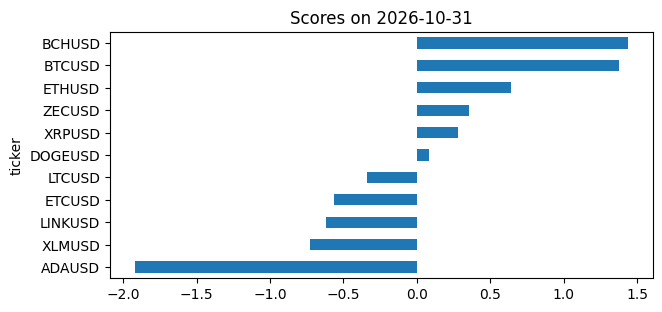

20335 rows, 11 coins, 2021-07-31 to 2026-10-31


In [5]:
import matplotlib.pyplot as plt

scores = models.score(model, closes)
last = scores[scores["date"] == scores["date"].max()].set_index("ticker")["score"].sort_values()
axes = last.plot.barh(figsize=(7, 3.2), title=f"Scores on {scores['date'].max()}")
plt.show()
print(f"{len(scores)} rows, {scores['ticker'].nunique()} coins, {scores['date'].min()} to {scores['date'].max()}")

*A score is not a result. Judge one with the IC report and the overfitting tests of the first notebooks before any book trades on it.*